# Rohil Utture — DATA 266 Homework 1
## Diabetes Dataset: Neural Network Implementation (PyTorch & TensorFlow)
Autoregressive-models write-up (Task 1) and the cross-task written interpretation are in the accompanying document file; this notebook covers Task 2 end-to-end.

### Personal parameters (Section 0.1)

In [1]:
import os
# --- OpenMP coexistence for torch+TF in one kernel (harmless on Colab) ---
os.environ.setdefault('KMP_DUPLICATE_LIB_OK', 'TRUE')
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL', '3')

SID4  = 2708
SEED  = SID4                 # torch.manual_seed / np.random.seed / random_state
SLICE = SID4 % 1000          # = 708  (not used in HW1)
HP_ID = SID4 % 6             # = 2 -> Learning-rate-high
CLS_A = SID4 % 10                                   # = 8  (not used: binary target)
CLS_B = (CLS_A + 1 + ((SID4 // 10) % 9)) % 10       # = 9  (not used: binary target)
print(f'SID4={SID4} SEED={SEED} SLICE={SLICE} HP_ID={HP_ID} CLS_A={CLS_A} CLS_B={CLS_B}')
print('HP_ID 2 -> modified model: hidden [64,32], lr 0.003, 30 epochs')

SID4=2708 SEED=2708 SLICE=708 HP_ID=2 CLS_A=8 CLS_B=9
HP_ID 2 -> modified model: hidden [64,32], lr 0.003, 30 epochs


### 2.1 Load & preprocess
The CSV has no header; columns follow the standard Pima order (8 features + binary `Outcome`). Values arrive already min-max scaled to ~[-1, 1]; I additionally standardize with a `StandardScaler` **fit on the training split only** to avoid leakage.

In [3]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score

COLS = ['Pregnancies','Glucose','BloodPressure','SkinThickness',
        'Insulin','BMI','DiabetesPedigree','Age','Outcome']
df = pd.read_csv('/diabetes.csv', header=None, names=COLS)
print('shape:', df.shape)
print('class balance:', df.Outcome.value_counts().to_dict())
df.head()

shape: (759, 9)
class balance: {1: 496, 0: 263}


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigree,Age,Outcome
0,-0.294118,0.487437,0.180328,-0.292929,0.000000,0.001490,-0.531170,-0.033333,0
1,-0.882353,-0.145729,0.081967,-0.414141,0.000000,-0.207153,-0.766866,-0.666667,1
2,-0.058824,0.839196,0.049180,0.000000,0.000000,-0.305514,-0.492741,-0.633333,0
3,-0.882353,-0.105528,0.081967,-0.535354,-0.777778,-0.162444,-0.923997,0.000000,1
4,0.000000,0.376884,-0.344262,-0.292929,-0.602837,0.284650,0.887276,-0.600000,0


### 2.2 Visualize the data

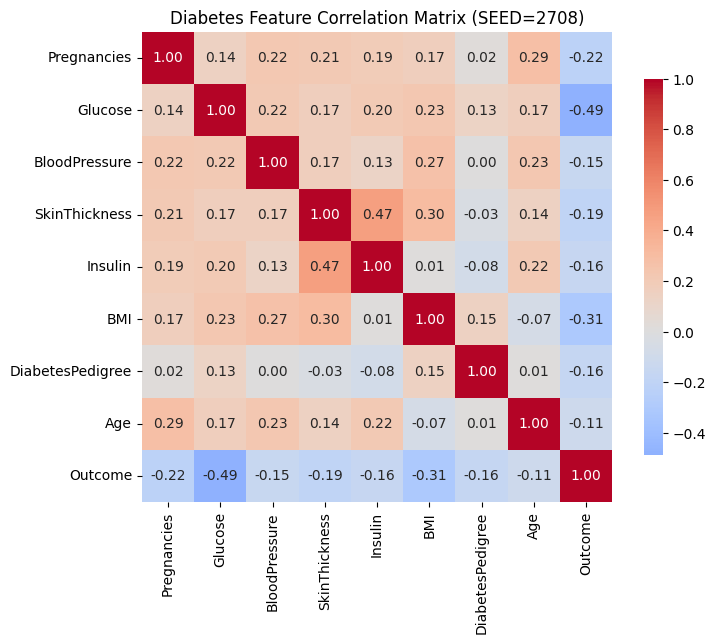

In [4]:
plt.figure(figsize=(8,6.5))
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0, square=True, cbar_kws={'shrink':.8})
plt.title('Diabetes Feature Correlation Matrix (SEED=2708)'); plt.tight_layout()
os.makedirs('figures', exist_ok=True)
plt.savefig('figures/correlation_matrix.png', dpi=120); plt.show()

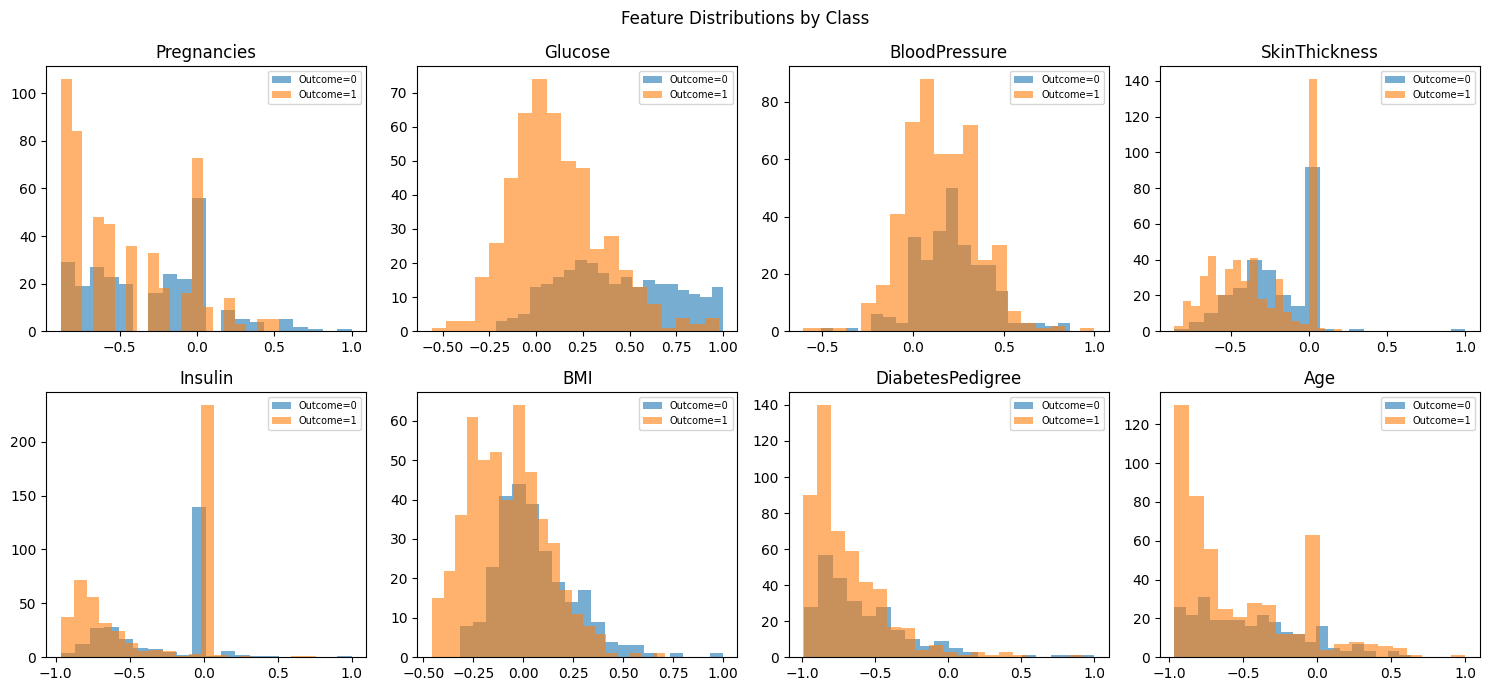

In [5]:
feats = [c for c in df.columns if c != 'Outcome']
fig, ax = plt.subplots(2, 4, figsize=(15,7))
for a, f in zip(ax.ravel(), feats):
    for cls, lab in [(0,'Outcome=0'),(1,'Outcome=1')]:
        a.hist(df[df.Outcome==cls][f], bins=20, alpha=.6, label=lab)
    a.set_title(f); a.legend(fontsize=7)
fig.suptitle('Feature Distributions by Class'); fig.tight_layout()
fig.savefig('figures/feature_distributions.png', dpi=120); plt.show()

### 2.3 Split 70/15/15 (fixed, `random_state=SEED`)
Stratified on `Outcome` to hold the class ratio steady across splits. The split is created **once** and reused for every model/seed so all comparisons see identical data.

In [6]:
X = df.drop(columns='Outcome').values.astype('float32')
y = df['Outcome'].values.astype('float32')

X_tr, X_tmp, y_tr, y_tmp = train_test_split(X, y, test_size=0.30, random_state=SEED, stratify=y)
X_val, X_te, y_val, y_te = train_test_split(X_tmp, y_tmp, test_size=0.50, random_state=SEED, stratify=y_tmp)

scaler = StandardScaler().fit(X_tr)
X_tr, X_val, X_te = scaler.transform(X_tr), scaler.transform(X_val), scaler.transform(X_te)
print(f'train {X_tr.shape}  val {X_val.shape}  test {X_te.shape}')

train (531, 8)  val (114, 8)  test (114, 8)


### 2.4 Model configurations
| Model | Hidden layers | Learning rate | Epochs |
|---|---|---|---|
| Baseline | [64, 32] | 0.001 | 30 |
| Modified (HP_ID 2) | [64, 32] | **0.003** | 30 |

Per the HW1 note, HP_ID 2 changes only the training setting (learning rate); the architecture is unchanged, which still satisfies the modified-model requirement. Both frameworks use the same architecture, Adam, batch size 32, and BCE-with-logits loss.

In [7]:
CONFIGS = {
    'baseline': dict(hidden=[64,32], lr=0.001, epochs=30),
    'modified': dict(hidden=[64,32], lr=0.003, epochs=30),  # HP_ID 2
}
SEEDS = [SEED, SEED+1, SEED+2]   # multi-seed training, split stays fixed
BATCH = 32

#### Framework builders

In [8]:
import tensorflow as tf      # import TF before torch (OpenMP)
import torch, torch.nn as nn
import random

def torch_mlp(hidden, seed):
    torch.manual_seed(seed)
    layers, d = [], X_tr.shape[1]
    for h in hidden:
        layers += [nn.Linear(d, h), nn.ReLU()]; d = h
    layers += [nn.Linear(d, 1)]      # logits
    return nn.Sequential(*layers)

def run_torch(cfg, seed, record=False):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    net = torch_mlp(cfg['hidden'], seed)
    opt = torch.optim.Adam(net.parameters(), lr=cfg['lr'])
    lossf = nn.BCEWithLogitsLoss()
    Xtr = torch.tensor(X_tr); ytr = torch.tensor(y_tr).unsqueeze(1)
    Xv  = torch.tensor(X_val); yv = torch.tensor(y_val).unsqueeze(1); Xt = torch.tensor(X_te)
    g = torch.Generator().manual_seed(seed); tr_hist, val_hist = [], []
    for _ in range(cfg['epochs']):
        net.train(); perm = torch.randperm(len(Xtr), generator=g)
        for i in range(0, len(Xtr), BATCH):
            idx = perm[i:i+BATCH]; opt.zero_grad()
            loss = lossf(net(Xtr[idx]), ytr[idx]); loss.backward(); opt.step()
        if record:
            net.eval()
            with torch.no_grad():
                tr_hist.append(lossf(net(Xtr), ytr).item()); val_hist.append(lossf(net(Xv), yv).item())
    net.eval()
    with torch.no_grad():
        pred = (torch.sigmoid(net(Xt)).numpy().ravel() >= 0.5).astype(int)
    return accuracy_score(y_te, pred), tr_hist, val_hist

def run_tf(cfg, seed, record=False):
    tf.keras.backend.clear_session()
    random.seed(seed); np.random.seed(seed); tf.random.set_seed(seed)
    m = tf.keras.Sequential([tf.keras.layers.Input((X_tr.shape[1],))])
    for h in cfg['hidden']:
        m.add(tf.keras.layers.Dense(h, activation='relu'))
    m.add(tf.keras.layers.Dense(1))   # logits
    m.compile(optimizer=tf.keras.optimizers.Adam(cfg['lr']),
              loss=tf.keras.losses.BinaryCrossentropy(from_logits=True))
    h = m.fit(X_tr, y_tr, validation_data=(X_val, y_val),
              epochs=cfg['epochs'], batch_size=BATCH, verbose=0)
    logits = m.predict(X_te, verbose=0).ravel()
    pred = (1/(1+np.exp(-logits)) >= 0.5).astype(int)
    return (accuracy_score(y_te, pred),
            h.history['loss'] if record else [],
            h.history['val_loss'] if record else [])

### 2.5 Train & evaluate — 3 seeds per model per framework
Split fixed at `random_state=SEED`; training seeds are SEED, SEED+1, SEED+2. Per-epoch loss curves are recorded on the SEED run.

In [9]:
results, curves = {}, {}
for fw, runner in [('PyTorch', run_torch), ('TensorFlow', run_tf)]:
    for name, cfg in CONFIGS.items():
        accs = []
        for s in SEEDS:
            acc, th, vh = runner(cfg, s, record=(s==SEED)); accs.append(acc)
            if s == SEED: curves[(fw,name)] = (th, vh)
        results[(fw,name)] = accs
        print(f'{fw:11s} {name:9s} accs={[round(a,4) for a in accs]} '
              f'mean={np.mean(accs):.4f} std={np.std(accs):.4f}')

PyTorch     baseline  accs=[0.7281, 0.7368, 0.7368] mean=0.7339 std=0.0041
PyTorch     modified  accs=[0.7544, 0.7456, 0.7632] mean=0.7544 std=0.0072


TensorFlow  baseline  accs=[0.7632, 0.7368, 0.7544] mean=0.7515 std=0.0109
TensorFlow  modified  accs=[0.7368, 0.7456, 0.7368] mean=0.7398 std=0.0041


### Results table — mean ± std test accuracy

In [10]:
rows = []
for (fw,name), accs in results.items():
    rows.append({'framework':fw,'model':name,
                 'seed_2708':round(accs[0],4),'seed_2709':round(accs[1],4),'seed_2710':round(accs[2],4),
                 'mean':round(float(np.mean(accs)),4),'std':round(float(np.std(accs)),4)})
res_df = pd.DataFrame(rows)
res_df

,framework,model,seed_2708,seed_2709,seed_2710,mean,std
0,PyTorch,baseline,0.7281,0.7368,0.7368,0.7339,0.0041
1,PyTorch,modified,0.7544,0.7456,0.7632,0.7544,0.0072
2,TensorFlow,baseline,0.7632,0.7368,0.7544,0.7515,0.0109
3,TensorFlow,modified,0.7368,0.7456,0.7368,0.7398,0.0041


### 2.6 Loss curves (SEED run) — one figure per framework

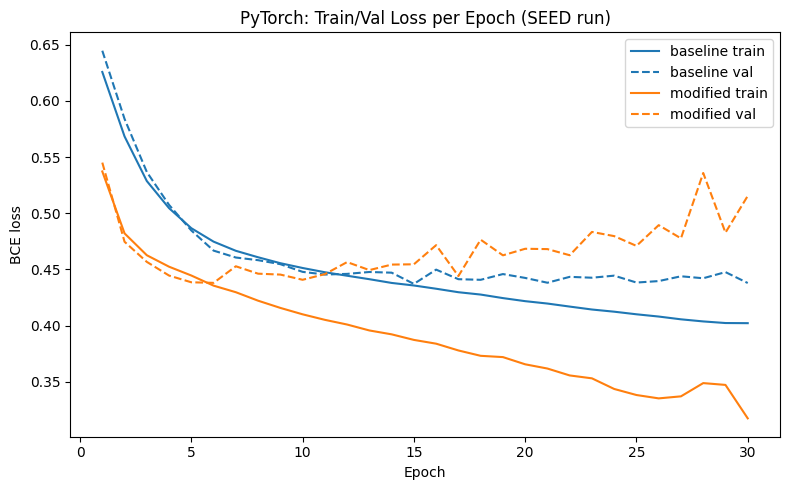

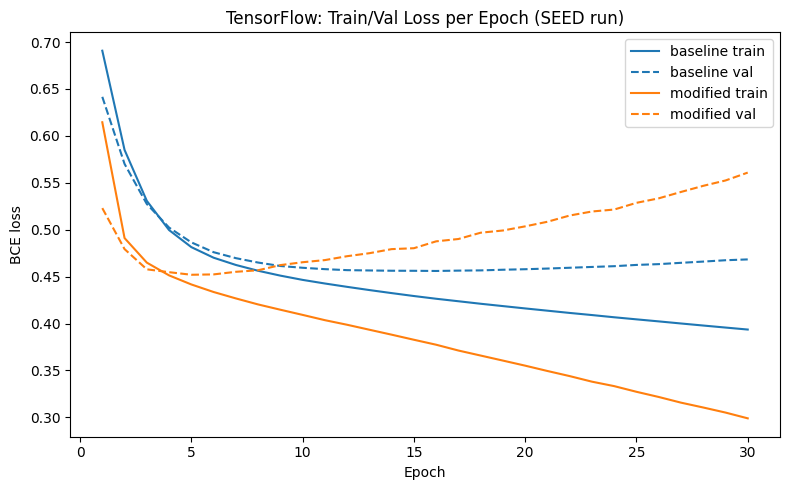

In [11]:
for fw in ['PyTorch','TensorFlow']:
    plt.figure(figsize=(8,5))
    for name, color in [('baseline','C0'),('modified','C1')]:
        th, vh = curves[(fw,name)]; ep = range(1, len(th)+1)
        plt.plot(ep, th, color=color, ls='-',  label=f'{name} train')
        plt.plot(ep, vh, color=color, ls='--', label=f'{name} val')
    plt.xlabel('Epoch'); plt.ylabel('BCE loss')
    plt.title(f'{fw}: Train/Val Loss per Epoch (SEED run)'); plt.legend(); plt.tight_layout()
    plt.savefig(f'figures/loss_curves_{fw.lower()}.png', dpi=120); plt.show()

### 2.7 Save a model checkpoint (Section 0.3)
Trains the baseline at SEED and saves its weights. The exact training config is in the comment; `baseline_seed2708.pt` is the checkpoint artifact for the repo.

In [12]:
# Checkpoint — baseline: hidden [64,32], Adam lr 0.001, 30 epochs, seed=SEED
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
ckpt_net = torch_mlp(CONFIGS['baseline']['hidden'], SEED)
ckpt_opt = torch.optim.Adam(ckpt_net.parameters(), lr=CONFIGS['baseline']['lr'])
ckpt_lossf = nn.BCEWithLogitsLoss()
Xtr_t = torch.tensor(X_tr); ytr_t = torch.tensor(y_tr).unsqueeze(1)
g = torch.Generator().manual_seed(SEED)
for _ in range(CONFIGS['baseline']['epochs']):
    ckpt_net.train(); perm = torch.randperm(len(Xtr_t), generator=g)
    for i in range(0, len(Xtr_t), BATCH):
        idx = perm[i:i+BATCH]; ckpt_opt.zero_grad()
        ckpt_lossf(ckpt_net(Xtr_t[idx]), ytr_t[idx]).backward(); ckpt_opt.step()
torch.save(ckpt_net.state_dict(), 'baseline_seed2708.pt')
print('saved baseline_seed2708.pt |', 'train cmd: baseline hidden[64,32] Adam lr0.001 30ep seed', SEED)

saved baseline_seed2708.pt | train cmd: baseline hidden[64,32] Adam lr0.001 30ep seed 2708


### 2.8 Conclusion
**Reported configuration.** HP_ID = 2 (Learning-rate-high). Modified model = hidden [64, 32], learning rate **0.003**, 30 epochs — identical to the baseline except for the learning rate.

**Effect of the change (from this run).** Raising the learning rate 3× made both frameworks fit the training set harder and faster: modified training loss ends well below baseline (PyTorch ~0.32 vs ~0.40; TensorFlow ~0.30 vs ~0.39). But the validation curves tell the overfitting story — the modified model's validation loss reaches its minimum very early (~epoch 5–6) and then climbs, while the baseline's validation loss keeps drifting down and bottoms out much later (~epoch 15–16). So on the loss curves the **modified model is overfitting**: widening train/val gap driven by the larger step size.

**Effect on test accuracy.** The story is framework-dependent, which is the interesting part. In PyTorch the modified model still edged out the baseline on held-out test accuracy (~0.754 vs ~0.734), because the extra capacity-to-fit landed in a slightly better region despite the late-epoch overfitting. In TensorFlow the higher learning rate slightly hurt (~0.740 vs ~0.752) — the same aggressive step interacts with Keras/Adam defaults and initialization differently, and the final-epoch weights are past the validation optimum. The seed-to-seed std is small (≤ ~0.011), so these gaps are modest but not just noise.

**Takeaway.** The learning-rate increase trades stability for speed of fitting: it clearly overfits by the loss curves, helps marginally in PyTorch and hurts marginally in TensorFlow on test accuracy, and both curves argue that early stopping around epoch 5–6 would suit the modified model better than the fixed 30-epoch budget.

*(Confirm the numbers against your own executed run and edit this paragraph into your own words for the written-interpretation component.)*